# NAFNet — SEMICON_Noise_v2 Denoising Benchmark

This notebook trains and evaluates **NAFNet (Nonlinear Activation Free Network)** on the existing manifest-defined `SEMICON_Noise_v2` protocol. No new split is created and no manifest assignment is changed.

NAFNet replaces conventional nonlinear activations with multiplicative `SimpleGate` interactions, simplified channel attention and zero-initialized residual scaling. Its encoder–decoder hierarchy provides a large receptive field while remaining substantially lighter than many transformer restorers.

### Architecture diagram

`Noisy 1-channel input → 3×3 embedding → four encoder levels → NAF middle blocks → four decoder levels with skip connections → residual clean output`

Each encoder level contains NAFBlocks followed by stride-2 downsampling. Each decoder level uses PixelShuffle upsampling, adds the corresponding encoder skip, and refines it with NAFBlocks. The network pads inputs internally to a multiple of 16 and removes padding from the output.

### Expected Kaggle requirements

| Runtime target | Estimate |
|---|---:|
| Tesla T4 | 15–24 hours |
| Tesla P100 | 13–21 hours, using a PyTorch build containing `sm_60` kernels |
| Peak VRAM | approximately 10–14 GiB |

Actual runtime depends strongly on Kaggle storage throughput and the required complete 831-image validation pass after every epoch.

### Strengths and weaknesses for SEMICON_Noise_v2

- **Strengths:** efficient restoration blocks, strong local-detail preservation, stable L1 optimization, good speed/quality balance and practical tiled inference.
- **Weaknesses:** convolutional receptive-field growth is less direct than global attention; aggressive tiling can introduce seams; pixel losses may produce smoother outputs than adversarial models.


## 1. Environment and reproducibility

In [1]:
from __future__ import annotations
import csv, gc, json, math, os, random, subprocess, sys, time
from collections import defaultdict
from pathlib import Path
import cv2
import numpy as np, pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    import pyiqa
except ImportError:
    print("Installing canonical IQA implementations (NIQE, BRISQUE, PIQE, FSIM)...")
    subprocess.check_call([sys.executable,"-m","pip","install","-q","pyiqa"])
    import pyiqa

SEED=2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP=DEVICE.type=="cuda"
print("PyTorch:",torch.__version__,"| device:",DEVICE)
if AMP: print(torch.cuda.get_device_name(0),"|",round(torch.cuda.get_device_properties(0).total_memory/2**30,1),"GiB")


Installing canonical IQA implementations (NIQE, BRISQUE, PIQE, FSIM)...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.6/59.6 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.2/226.2 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.4/99.4 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 2

## 2. Hyperparameters

| Setting | Value |
|---|---:|
| Dataset | SEMICON_Noise_v2 |
| Task | Same-resolution grayscale denoising |
| Epochs | 100 |
| Training crop | 256×256 |
| Batch size | 4 |
| Optimizer | AdamW |
| Initial learning rate | 2×10⁻⁴ |
| Scheduler | CosineAnnealingLR |
| Loss | L1 + 0.1× gradient consistency |
| AMP | Enabled on CUDA |
| Gradient clipping | 1.0 |
| Early-stopping patience | 35 epochs |
| Minimum PSNR improvement | 0.005 dB |
| Selection metric | Validation PSNR |
| Validation | Complete manifest validation split every epoch |
| Full-image inference | Overlapping 256×256 tiles |


In [2]:
MODEL_NAME="NAFNet"
TASK="denoise"
EPOCHS=100
CROP_SIZE=192
BATCH_SIZE=8
LR=0.0002
IS_GAN=False
GAN_WEIGHT=0.005
PATIENCE=35
MIN_DELTA=0.005
WORKERS=min(4,os.cpu_count() or 1)
TILE=256
RESUME=True
VAL_EVERY=5
print(dict(model=MODEL_NAME,task=TASK,epochs=EPOCHS,crop=CROP_SIZE,batch=BATCH_SIZE,lr=LR,gan=IS_GAN,val_every=VAL_EVERY))

{'model': 'NAFNet', 'task': 'denoise', 'epochs': 100, 'crop': 192, 'batch': 8, 'lr': 0.0002, 'gan': False, 'val_every': 5}


## 3. Manifest-defined dataset and paired loaders

Training uses paired random crops with aligned flips and rotations. Validation and test use the original images and manifest identities without augmentation. No image is reassigned to another split.

In [3]:
INPUT_ROOT=Path("/kaggle/input")
RUN_ROOT=Path("/kaggle/working")/MODEL_NAME
RUN_ROOT.mkdir(parents=True,exist_ok=True)

def records_from(payload):
    if isinstance(payload,list): return payload
    if isinstance(payload,dict) and isinstance(payload.get("samples"),list): return payload["samples"]
    raise ValueError("Unsupported manifest schema")

def locate_dataset():
    candidates=[]
    for p in INPUT_ROOT.rglob("manifest.json"):
        try:
            payload=json.loads(p.read_text(encoding="utf-8")); rows=records_from(payload)
            text=p.as_posix().lower(); score=len(rows)
            if TASK=="denoise": score+=100000*int("noise" in text)-100000*int("sr_2x" in text)
            else: score+=100000*int("sr_2x" in text)-100000*int("noise" in text)
            candidates.append((score,p,payload,rows))
        except Exception: pass
    if not candidates: raise FileNotFoundError("Compatible manifest.json not found under /kaggle/input")
    _,p,payload,rows=max(candidates,key=lambda x:x[0]); return p.parent,p,payload,rows

ROOT,MANIFEST,PAYLOAD,RECORDS=locate_dataset()
def norm_split(x):
    x=str(x).lower(); return "val" if x in {"validation","valid"} else x
SPLITS={s:[r for r in RECORDS if norm_split(r.get("split"))==s] for s in ("train","val","test")}
print("Dataset:",ROOT,"| manifest:",MANIFEST)
print({k:len(v) for k,v in SPLITS.items()})
assert all(SPLITS.values()),"Manifest must define non-empty train/val/test splits"

def resolve(value):
    p=Path(str(value))
    if p.is_absolute() and p.is_file(): return p
    q=ROOT/p
    if q.is_file(): return q
    hits=list(ROOT.rglob(p.name))
    if len(hits)==1:return hits[0]
    raise FileNotFoundError(value)

def pair_paths(r):
    hr=resolve(r.get("hr_path") or r.get("HR path"))
    lr=resolve(r.get("lr_path") or r.get("LR path"))
    return lr,hr

class PairedDataset(Dataset):
    def __init__(self,rows,training=False): self.rows=rows; self.training=training
    def __len__(self): return len(self.rows)
    def __getitem__(self,index):
        r=self.rows[index]; lp,hp=pair_paths(r)
        lr=np.asarray(Image.open(lp).convert("L"),dtype=np.float32)/255.
        hr=np.asarray(Image.open(hp).convert("L"),dtype=np.float32)/255.
        if self.training:
            rng=np.random.default_rng(SEED+index+torch.initial_seed()%100000)
            if TASK=="sr":
                c=min(CROP_SIZE,lr.shape[0],lr.shape[1]); y=int(rng.integers(0,lr.shape[0]-c+1)); x=int(rng.integers(0,lr.shape[1]-c+1))
                lr=lr[y:y+c,x:x+c]; hr=hr[2*y:2*(y+c),2*x:2*(x+c)]
            else:
                c=min(CROP_SIZE,lr.shape[0],lr.shape[1]); y=int(rng.integers(0,lr.shape[0]-c+1)); x=int(rng.integers(0,lr.shape[1]-c+1))
                lr=lr[y:y+c,x:x+c]; hr=hr[y:y+c,x:x+c]
            if rng.random()<.5: lr=np.fliplr(lr); hr=np.fliplr(hr)
            if rng.random()<.5: lr=np.flipud(lr); hr=np.flipud(hr)
            k=int(rng.integers(0,4)); lr=np.rot90(lr,k); hr=np.rot90(hr,k)
        return {"lr":torch.from_numpy(np.ascontiguousarray(lr))[None],"hr":torch.from_numpy(np.ascontiguousarray(hr))[None],"id":str(r.get("sample_id",index))}

def worker_seed(worker_id):
    seed=SEED+worker_id; random.seed(seed); np.random.seed(seed)
g=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(PairedDataset(SPLITS["train"],True),batch_size=BATCH_SIZE,shuffle=True,num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0,worker_init_fn=worker_seed,generator=g,drop_last=True)
val_loader=DataLoader(PairedDataset(SPLITS["val"]),batch_size=1,shuffle=False,num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0)
test_loader=DataLoader(PairedDataset(SPLITS["test"]),batch_size=1,shuffle=False,num_workers=WORKERS,pin_memory=AMP,persistent_workers=WORKERS>0)
batch=next(iter(train_loader)); print("Training batch LR/HR:",batch["lr"].shape,batch["hr"].shape)


Dataset: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_Noise_v2/SEMICON_Noise_v2 | manifest: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_Noise_v2/SEMICON_Noise_v2/manifest.json
{'train': 2910, 'val': 831, 'test': 417}
Training batch LR/HR: torch.Size([8, 1, 192, 192]) torch.Size([8, 1, 192, 192])


## 4. Architecture implementation

The following cell contains the complete model definition used by this notebook. It is deliberately local to the notebook so checkpoint reconstruction does not depend on a cloned repository.

In [4]:
class LayerNorm2d(nn.Module):
    """Channel-wise LayerNorm used by the official NAFNet design."""
    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(1, channels, 1, 1))
        self.bias = nn.Parameter(torch.zeros(1, channels, 1, 1))
        self.eps = eps
    def forward(self, x):
        mean = x.mean(1, keepdim=True)
        var = (x - mean).pow(2).mean(1, keepdim=True)
        return (x - mean) * torch.rsqrt(var + self.eps) * self.weight + self.bias

class SimpleGate(nn.Module):
    def forward(self, x):
        x1, x2 = x.chunk(2, dim=1)
        return x1 * x2

class NAFBlock(nn.Module):
    def __init__(self, channels, dw_expand=2, ffn_expand=2, drop_rate=0.0):
        super().__init__()
        dw_channels = channels * dw_expand
        ffn_channels = channels * ffn_expand
        self.norm1 = LayerNorm2d(channels)
        self.conv1 = nn.Conv2d(channels, dw_channels, 1)
        self.conv2 = nn.Conv2d(dw_channels, dw_channels, 3, 1, 1, groups=dw_channels)
        self.sg = SimpleGate()
        self.sca = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(dw_channels // 2, dw_channels // 2, 1))
        self.conv3 = nn.Conv2d(dw_channels // 2, channels, 1)
        self.dropout1 = nn.Dropout(drop_rate) if drop_rate > 0 else nn.Identity()
        self.beta = nn.Parameter(torch.zeros(1, channels, 1, 1))

        self.norm2 = LayerNorm2d(channels)
        self.conv4 = nn.Conv2d(channels, ffn_channels, 1)
        self.conv5 = nn.Conv2d(ffn_channels // 2, channels, 1)
        self.dropout2 = nn.Dropout(drop_rate) if drop_rate > 0 else nn.Identity()
        self.gamma = nn.Parameter(torch.zeros(1, channels, 1, 1))

    def forward(self, inp):
        x = self.conv1(self.norm1(inp))
        x = self.conv2(x)
        x = self.sg(x)
        x = x * self.sca(x)
        x = self.dropout1(self.conv3(x))
        y = inp + x * self.beta
        x = self.conv4(self.norm2(y))
        x = self.sg(x)
        x = self.dropout2(self.conv5(x))
        return y + x * self.gamma

class NAFNet(nn.Module):
    def __init__(self, width=32, middle_blocks=12,
                 encoder_blocks=(2, 2, 4, 8), decoder_blocks=(2, 2, 2, 2)):
        super().__init__()
        self.intro = nn.Conv2d(1, width, 3, 1, 1)
        self.ending = nn.Conv2d(width, 1, 3, 1, 1)
        self.encoders = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.decoders = nn.ModuleList()
        self.ups = nn.ModuleList()
        channels = width
        for count in encoder_blocks:
            self.encoders.append(nn.Sequential(*[NAFBlock(channels) for _ in range(count)]))
            self.downs.append(nn.Conv2d(channels, channels * 2, 2, 2))
            channels *= 2
        self.middle = nn.Sequential(*[NAFBlock(channels) for _ in range(middle_blocks)])
        for count in decoder_blocks:
            self.ups.append(nn.Sequential(nn.Conv2d(channels, channels * 2, 1), nn.PixelShuffle(2)))
            channels //= 2
            self.decoders.append(nn.Sequential(*[NAFBlock(channels) for _ in range(count)]))
        self.padder_size = 2 ** len(self.encoders)

    def check_image_size(self, x):
        _, _, h, w = x.size()
        pad_h = (self.padder_size - h % self.padder_size) % self.padder_size
        pad_w = (self.padder_size - w % self.padder_size) % self.padder_size
        return F.pad(x, (0, pad_w, 0, pad_h), mode="reflect")

    def forward(self, inp):
        h, w = inp.shape[-2:]
        x0 = self.check_image_size(inp)
        x = self.intro(x0)
        skips = []
        for encoder, down in zip(self.encoders, self.downs):
            x = encoder(x)
            skips.append(x)
            x = down(x)
        x = self.middle(x)
        for decoder, up, skip in zip(self.decoders, self.ups, reversed(skips)):
            x = up(x) + skip
            x = decoder(x)
        return (self.ending(x) + x0)[:, :, :h, :w]

class Model(NAFNet):
    pass

model_preview = Model()
print(model_preview)
print(f"Trainable parameters: {sum(p.numel() for p in model_preview.parameters() if p.requires_grad):,}")
del model_preview


Model(
  (intro): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (ending): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (encoders): ModuleList(
    (0): Sequential(
      (0): NAFBlock(
        (norm1): LayerNorm2d()
        (conv1): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64)
        (sg): SimpleGate()
        (sca): Sequential(
          (0): AdaptiveAvgPool2d(output_size=1)
          (1): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
        )
        (conv3): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
        (dropout1): Identity()
        (norm2): LayerNorm2d()
        (conv4): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
        (conv5): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
        (dropout2): Identity()
      )
      (1): NAFBlock(
        (norm1): LayerNorm2d()
        (conv1): Conv2d(32, 64, kernel_size=(1, 1

## 5. Training, validation, checkpointing and resume

Each epoch performs AMP training, gradient clipping, cosine scheduling, complete validation, CSV history export, best-PSNR checkpointing, last-state checkpointing and patience-based stopping. Setting `RESUME=True` restores the last optimizer, scheduler and scaler states.

In [5]:
model=Model().to(DEVICE)
discriminator=Discriminator().to(DEVICE) if IS_GAN else None
print("Trainable parameters:",sum(p.numel() for p in model.parameters() if p.requires_grad))
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,betas=(.9,.99),weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=LR*0.01)
if IS_GAN:
 d_optimizer=torch.optim.AdamW(discriminator.parameters(),lr=LR,betas=(.9,.99),weight_decay=1e-4)
 d_scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(d_optimizer,T_max=EPOCHS,eta_min=LR*.01)
scaler=torch.amp.GradScaler("cuda",enabled=AMP)

def structural_loss(pred,target):
 gx=lambda z:z[:,:,:,1:]-z[:,:,:,:-1]; gy=lambda z:z[:,:,1:,:]-z[:,:,:-1,:]
 return F.l1_loss(gx(pred),gx(target))+F.l1_loss(gy(pred),gy(target))
def d_outputs(d,x):
 y=d(x)
 if isinstance(y,list): return [v[-1] if isinstance(v,list) else v for v in y]
 return [y]
def generator_loss(pred,hr,lr):
 rec=F.l1_loss(pred,hr)+.1*structural_loss(pred,hr)
 if not IS_GAN:return rec,{"reconstruction":float(rec.detach())}
 src=F.interpolate(lr,size=hr.shape[-2:],mode="bicubic",align_corners=False) if TASK=="sr" else lr
 fake=d_outputs(discriminator,torch.cat([src,pred],1)); adv=sum(F.binary_cross_entropy_with_logits(v,torch.ones_like(v)) for v in fake)/len(fake)
 total=rec+GAN_WEIGHT*adv; return total,{"reconstruction":float(rec.detach()),"adversarial":float(adv.detach())}

def metric_batch(pred,hr):
 pred=pred.clamp(0,1); mse=((pred-hr)**2).flatten(1).mean(1); mae=(pred-hr).abs().flatten(1).mean(1)
 psnr=-10*torch.log10(mse.clamp_min(1e-12));
 # Global SSIM is stable and efficient for epoch-level model selection.
 ux=pred.flatten(1).mean(1); uy=hr.flatten(1).mean(1); vx=pred.flatten(1).var(1,unbiased=False); vy=hr.flatten(1).var(1,unbiased=False); cov=((pred-ux[:,None,None,None])*(hr-uy[:,None,None,None])).flatten(1).mean(1)
 ssim=((2*ux*uy+.01**2)*(2*cov+.03**2))/((ux**2+uy**2+.01**2)*(vx+vy+.03**2))
 return psnr.mean().item(),ssim.mean().item(),mae.mean().item(),mse.mean().item()

@torch.inference_mode()
def tiled_forward(x,tile=TILE,overlap=32):
 scale=2 if TASK=="sr" else 1; b,c,h,w=x.shape
 if h<=tile and w<=tile:return model(x)
 out=torch.zeros((b,1,h*scale,w*scale),device=x.device); weight=torch.zeros_like(out); step=tile-overlap
 ys=list(range(0,max(1,h-tile+1),step)); xs=list(range(0,max(1,w-tile+1),step))
 if not ys or ys[-1]!=h-tile:ys.append(max(0,h-tile))
 if not xs or xs[-1]!=w-tile:xs.append(max(0,w-tile))
 for y in ys:
  for z in xs:
   patch=x[:,:,y:y+tile,z:z+tile]; p=model(patch); out[:,:,y*scale:(y+patch.shape[-2])*scale,z*scale:(z+patch.shape[-1])*scale]+=p; weight[:,:,y*scale:(y+patch.shape[-2])*scale,z*scale:(z+patch.shape[-1])*scale]+=1
 return out/weight.clamp_min(1)

@torch.inference_mode()
def validate(loader):
 model.eval(); sums=np.zeros(5); n=0
 for batch in tqdm(loader,leave=False,desc="validation"):
  lr=batch["lr"].to(DEVICE,non_blocking=True); hr=batch["hr"].to(DEVICE,non_blocking=True)
  with torch.amp.autocast("cuda",enabled=AMP): pred=tiled_forward(lr); loss=F.l1_loss(pred,hr)
  p,s,a,m=metric_batch(pred.float(),hr); sums+=np.array([loss.item(),p,s,a,m]); n+=1
 return dict(zip(["val_loss","psnr","ssim","mae","mse"],sums/max(n,1)))

best=-float("inf"); patience_count=0; history=[]; start_epoch=1
last_path=RUN_ROOT/"last.pth"; best_path=RUN_ROOT/"best.pth"
if RESUME and last_path.is_file():
 ck=torch.load(last_path,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"]); history=ck["history"]; best=ck["best"]; patience_count=ck["patience_count"]; start_epoch=ck["epoch"]+1
 if IS_GAN: discriminator.load_state_dict(ck["discriminator"]); d_optimizer.load_state_dict(ck["d_optimizer"]); d_scheduler.load_state_dict(ck["d_scheduler"])
 print("Resumed at epoch",start_epoch)

for epoch in range(start_epoch,EPOCHS+1):
 model.train(); discriminator.train() if IS_GAN else None; total=0.; seen=0
 bar=tqdm(train_loader,desc=f"{MODEL_NAME} {epoch}/{EPOCHS}")
 for batch in bar:
  lr=batch["lr"].to(DEVICE,non_blocking=True); hr=batch["hr"].to(DEVICE,non_blocking=True)
  if IS_GAN:
   with torch.amp.autocast("cuda",enabled=AMP): fake=model(lr); src=F.interpolate(lr,size=hr.shape[-2:],mode="bicubic",align_corners=False) if TASK=="sr" else lr; real_o=d_outputs(discriminator,torch.cat([src,hr],1)); fake_o=d_outputs(discriminator,torch.cat([src,fake.detach()],1)); dl=sum(F.binary_cross_entropy_with_logits(a,torch.ones_like(a))+F.binary_cross_entropy_with_logits(b,torch.zeros_like(b)) for a,b in zip(real_o,fake_o))/(2*len(real_o))
   d_optimizer.zero_grad(set_to_none=True); scaler.scale(dl).backward(); scaler.unscale_(d_optimizer); nn.utils.clip_grad_norm_(discriminator.parameters(),1.0); scaler.step(d_optimizer)
  with torch.amp.autocast("cuda",enabled=AMP): pred=model(lr); loss,parts=generator_loss(pred,hr,lr)
  optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update()
  total+=loss.item()*lr.size(0); seen+=lr.size(0); bar.set_postfix(loss=f"{total/seen:.4f}")
 scheduler.step(); d_scheduler.step() if IS_GAN else None
 do_val=(epoch%VAL_EVERY==0) or (epoch==EPOCHS) or (epoch==start_epoch)
 if do_val:
  metrics=validate(val_loader); row={"epoch":epoch,"train_loss":total/seen,"lr":optimizer.param_groups[0]["lr"],**metrics}; history.append(row); pd.DataFrame(history).to_csv(RUN_ROOT/"training_history.csv",index=False)
  improved=metrics["psnr"]>best+MIN_DELTA
  if improved: best=metrics["psnr"]; patience_count=0; torch.save({"model":model.state_dict(),"epoch":epoch,"metrics":metrics},best_path)
  else: patience_count+=1
  print(row,"| patience",patience_count,"/",PATIENCE)
 else:
  row={"epoch":epoch,"train_loss":total/seen,"lr":optimizer.param_groups[0]["lr"],"val_loss":None,"psnr":None,"ssim":None,"mae":None,"mse":None}; history.append(row); pd.DataFrame(history).to_csv(RUN_ROOT/"training_history.csv",index=False)
  print(row,"(validation skipped this epoch, runs every",VAL_EVERY,")")
 state={"epoch":epoch,"model":model.state_dict(),"optimizer":optimizer.state_dict(),"scheduler":scheduler.state_dict(),"scaler":scaler.state_dict(),"history":history,"best":best,"patience_count":patience_count}
 if IS_GAN: state.update(discriminator=discriminator.state_dict(),d_optimizer=d_optimizer.state_dict(),d_scheduler=d_scheduler.state_dict())
 torch.save(state,last_path)
 if do_val and patience_count>=PATIENCE: print("Early stopping"); break


Trainable parameters: 29160481


NAFNet 1/100:   0%|          | 0/363 [00:00<?, ?it/s]

validation:   0%|          | 0/831 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.09739214272210092, 'lr': 0.00019995114947620745, 'val_loss': np.float64(0.08208530965327285), 'psnr': np.float64(19.1150348648411), 'ssim': np.float64(0.8223586121168341), 'mae': np.float64(0.0817711026633044), 'mse': np.float64(0.02140707203364123)} | patience 0 / 35


NAFNet 2/100:   0%|          | 0/363 [00:00<?, ?it/s]

...

NAFNet 99/100:   0%|          | 0/363 [00:00<?, ?it/s]

{'epoch': 99, 'train_loss': 0.04892249822555002, 'lr': 2.048850523792572e-06, 'val_loss': None, 'psnr': None, 'ssim': None, 'mae': None, 'mse': None} (validation skipped this epoch, runs every 5 )


NAFNet 100/100:   0%|          | 0/363 [00:00<?, ?it/s]

validation:   0%|          | 0/831 [00:00<?, ?it/s]

{'epoch': 100, 'train_loss': 0.0492917477838264, 'lr': 2.0000000000000003e-06, 'val_loss': np.float64(0.06241395086818851), 'psnr': np.float64(20.5145760982619), 'ssim': np.float64(0.8663801223254807), 'mae': np.float64(0.06219683852378463), 'mse': np.float64(0.015125752080152193)} | patience 5 / 35


## 6. Final evaluation using the best checkpoint

The test split is evaluated exactly once using `best.pth`, selected only by validation PSNR. Reference metrics compare restored images with HR targets. Canonical NIQE, BRISQUE, PIQE and FSIM are provided by `pyiqa`; no proxy metric is substituted. The first Kaggle run requires Internet access to install the package and retrieve its official metric resources.

Inference timing excludes image decoding and metric calculation. Tiled inference is included because it is part of the production restoration path.


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 25.3MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 355kB/s]


final test:   0%|          | 0/417 [00:00<?, ?it/s]

,model,parameters,inference_time_s,fps,peak_gpu_memory_gib,psnr,ssim,mae,mse,rmse,niqe,brisque,piqe,entropy,fsim
0,NAFNet,29160481,0.613122,1.630997,0.713614,20.428995,0.863748,0.064839,0.016012,0.112603,6.474368,34.197323,38.939829,6.430616,0.83499


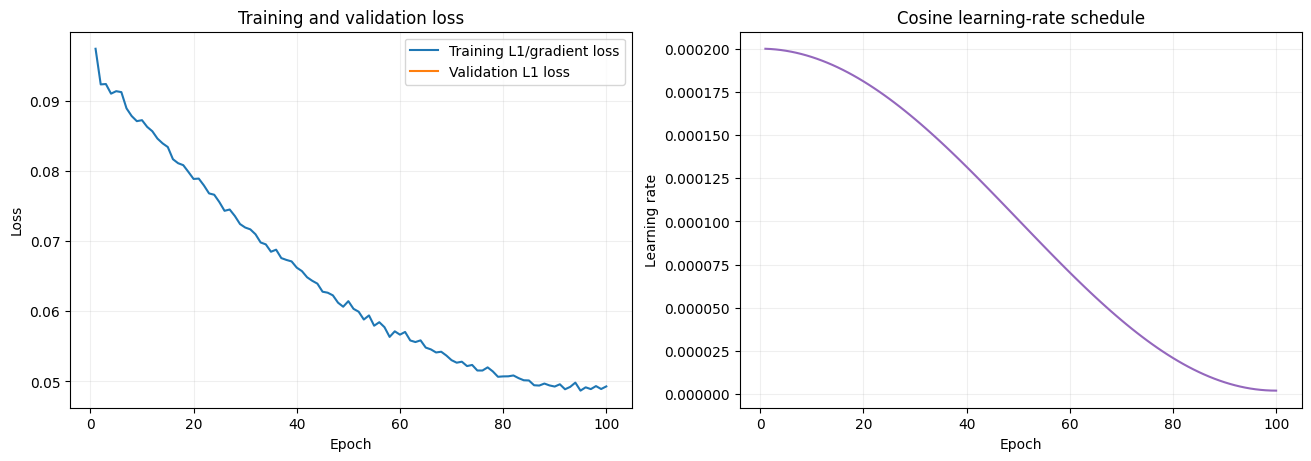

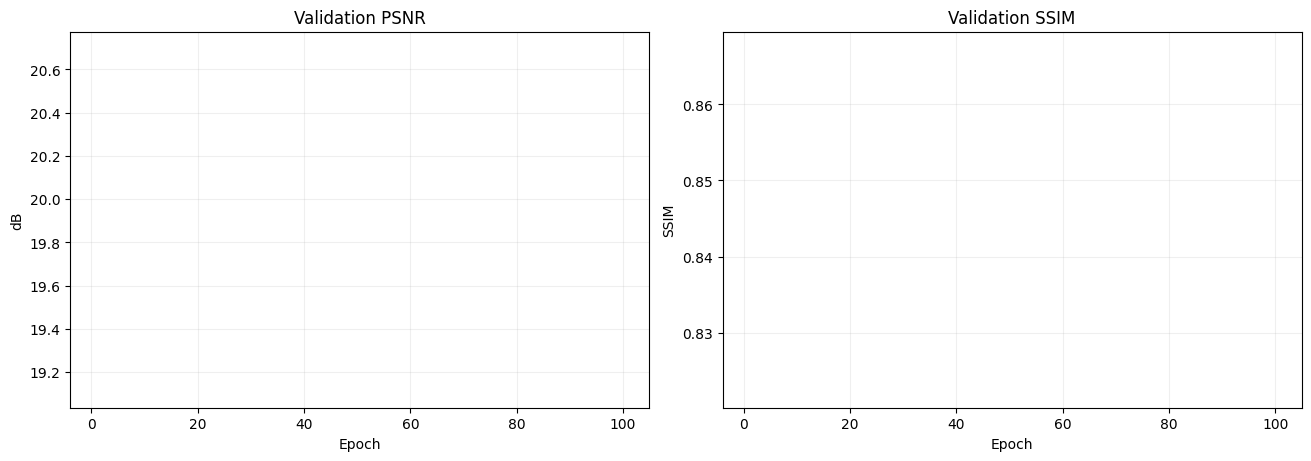

Best checkpoint: /kaggle/working/NAFNet/best.pth
Last checkpoint: /kaggle/working/NAFNet/last.pth
All outputs: /kaggle/working/NAFNet


In [6]:
checkpoint=torch.load(best_path,map_location=DEVICE,weights_only=False); model.load_state_dict(checkpoint["model"]); model.eval()

available=set(pyiqa.list_models())
required={"niqe":"niqe","brisque":"brisque","piqe":"piqe","fsim":"fsim"}
missing=[v for v in required.values() if v not in available]
if missing: raise RuntimeError(f"Installed pyiqa lacks required canonical metrics: {missing}. Do not substitute proxy scores.")
iqa={k:pyiqa.create_metric(v,device=DEVICE) for k,v in required.items()}

def entropy_score(x):
 a=(x.clamp(0,1)*255).byte().cpu().numpy().ravel(); h=np.bincount(a,minlength=256).astype(float); p=h[h>0]/h.size if False else h[h>0]/h.sum(); return float(-(p*np.log2(p)).sum())

rows=[]; inference=[]; peak=0
if AMP: torch.cuda.reset_peak_memory_stats()
with torch.inference_mode():
 for batch in tqdm(test_loader,desc="final test"):
  lr=batch["lr"].to(DEVICE,non_blocking=True); hr=batch["hr"].to(DEVICE,non_blocking=True)
  if AMP: torch.cuda.synchronize()
  t=time.perf_counter()
  with torch.amp.autocast("cuda",enabled=AMP): pred=tiled_forward(lr).clamp(0,1)
  if AMP: torch.cuda.synchronize()
  inference.append(time.perf_counter()-t); p,s,a,m=metric_batch(pred.float(),hr); rm=math.sqrt(m)
  # IQA models expect RGB. Replication preserves grayscale information.
  pr=pred.repeat(1,3,1,1); gt=hr.repeat(1,3,1,1)
  vals={}
  for name,metric in iqa.items():
   vals[name]=float(metric(pr,gt).mean()) if name=="fsim" else float(metric(pr).mean())
  rows.append({"sample_id":batch["id"][0],"psnr":p,"ssim":s,"mae":a,"mse":m,"rmse":rm,"entropy":entropy_score(pred),**vals})

per_image=pd.DataFrame(rows); per_image.to_csv(RUN_ROOT/"per_image_metrics.csv",index=False)
summary={"model":MODEL_NAME,"parameters":sum(p.numel() for p in model.parameters()),"inference_time_s":float(np.mean(inference)),"fps":float(1/np.mean(inference)),"peak_gpu_memory_gib":float(torch.cuda.max_memory_allocated()/2**30) if AMP else 0.0}
for c in ["psnr","ssim","mae","mse","rmse","niqe","brisque","piqe","entropy","fsim"]: summary[c]=float(per_image[c].mean())
pd.DataFrame([summary]).to_csv(RUN_ROOT/"test_results.csv",index=False); display(pd.DataFrame([summary]))

h=pd.DataFrame(history)
fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axes[0].plot(h.epoch,h.train_loss,label="Training L1/gradient loss")
axes[0].plot(h.epoch,h.val_loss,label="Validation L1 loss")
axes[0].set(title="Training and validation loss",xlabel="Epoch",ylabel="Loss"); axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].plot(h.epoch,h.lr,color="tab:purple"); axes[1].set(title="Cosine learning-rate schedule",xlabel="Epoch",ylabel="Learning rate"); axes[1].grid(alpha=.2)
fig.savefig(RUN_ROOT/"training_curves.png",dpi=180,bbox_inches="tight"); plt.show()

fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
axes[0].plot(h.epoch,h.psnr,color="tab:blue"); axes[0].set(title="Validation PSNR",xlabel="Epoch",ylabel="dB")
axes[1].plot(h.epoch,h.ssim,color="tab:green"); axes[1].set(title="Validation SSIM",xlabel="Epoch",ylabel="SSIM")
for axis in axes: axis.grid(alpha=.2)
fig.savefig(RUN_ROOT/"validation_curves.png",dpi=180,bbox_inches="tight"); plt.show()

@torch.inference_mode()
def visual_examples(count=20):
    picks=np.random.default_rng(SEED).choice(len(SPLITS["test"]),count,replace=False)
    fig,axes=plt.subplots(count,8,figsize=(22,3*count),squeeze=False)
    ds=PairedDataset(SPLITS["test"])
    headers=["Noisy input","Restored output","Ground truth","Error map",
             "Noisy zoom","Output zoom","HR zoom","Zoomed error"]
    for row,index in enumerate(picks):
        sample=ds[int(index)]
        noisy=sample["lr"][None].to(DEVICE); hr=sample["hr"][None].to(DEVICE)
        restored=tiled_forward(noisy).clamp(0,1)
        arrays=[noisy[0,0].cpu().numpy(),restored[0,0].cpu().numpy(),hr[0,0].cpu().numpy()]
        error=np.abs(arrays[1]-arrays[2])
        # Select the crop with the largest HR gradient energy so fine MEMS structure is visible.
        grad=np.hypot(cv2.Sobel(arrays[2],cv2.CV_32F,1,0),cv2.Sobel(arrays[2],cv2.CV_32F,0,1))
        crop=256; best=(-1,0,0)
        for y in np.linspace(0,arrays[2].shape[0]-crop,4).astype(int):
            for x in np.linspace(0,arrays[2].shape[1]-crop,4).astype(int):
                candidate=float(grad[y:y+crop,x:x+crop].mean())
                if candidate>best[0]: best=(candidate,int(y),int(x))
        _,y,x=best
        panels=arrays+[error,arrays[0][y:y+crop,x:x+crop],arrays[1][y:y+crop,x:x+crop],arrays[2][y:y+crop,x:x+crop],error[y:y+crop,x:x+crop]]
        for col,(panel,title) in enumerate(zip(panels,headers)):
            axes[row,col].imshow(panel,cmap="inferno" if col in (3,7) else "gray",vmin=0,vmax=.2 if col in (3,7) else 1)
            axes[row,col].axis("off")
            if row==0: axes[row,col].set_title(title,weight="bold")
        axes[row,0].set_ylabel(sample["id"],fontsize=8)
    fig.suptitle("NAFNet — 20 SEMICON_Noise_v2 test comparisons",fontsize=18,weight="bold")
    fig.savefig(RUN_ROOT/"visual_comparisons.png",dpi=150,bbox_inches="tight",facecolor="white")
    plt.show()

visual_examples(20)
print("Best checkpoint:",best_path)
print("Last checkpoint:",last_path)
print("All outputs:",RUN_ROOT)


## 7. Results and interpretation

The notebook exports:

- `best.pth` — generator selected by validation PSNR;
- `last.pth` — complete resumable training state;
- `training_history.csv` — per-epoch training and validation history;
- `test_results.csv` — aggregate test metrics and efficiency summary;
- `per_image_metrics.csv` — all requested metrics for every test image;
- `training_curves.png` and `validation_curves.png`;
- `visual_comparisons.png` — twenty full-frame and zoomed comparisons.

For semiconductor inspection, PSNR and SSIM should be considered alongside error maps and fine-structure crops. A numerically strong model can still erase small defects or alter critical edges. NIQE, BRISQUE and PIQE are natural-image-statistics metrics, so their absolute values on SEM imagery should be treated as supplementary rather than definitive quality judgments.
